# 06 — Figuras de desempenho: matrizes de confusão e curvas ROC

Gera as figuras da seção 8.2 a partir dos modelos **selecionados para implantação** (sem novo treino):

* **Matrizes de confusão:** (a) CNN 2D int8 v3 no teste do MIMII (janelas de 1 s); (b) LSTM float32 nas **janelas reais** do teste do Bristol (quatro classes).
* **Curvas ROC:** (a) CNN no teste do MIMII, com a AUC e o ponto do limiar 0,5; (b) teste de máquina nova, uma curva por ventilador deixado de fora (CNN v3, linha de base de cada máquina).

Pré-requisitos: notebooks 03 v3 (com a célula 8, que salva `predicoes_maquina_nova.npz`) e 04. Saídas em PNG (300 dpi) e SVG em `dissertacao_tinyml/figuras/`.

In [1]:
# 1. Ambiente e caminhos
import os, sys, json, subprocess, importlib.util
if importlib.util.find_spec("tensorflow") is None:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "tensorflow==2.21.0"], check=True)
import numpy as np, pandas as pd, tensorflow as tf, matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/dissertacao_tinyml"
except ImportError:
    BASE = os.environ.get("BASE_TINYML", "dissertacao_tinyml")
try:
    from ai_edge_litert.interpreter import Interpreter
except ImportError:
    Interpreter = tf.lite.Interpreter
MIMII, CNN, LSTM, BRISTOL = (f"{BASE}/{p}" for p in ["mimii_fan_6db", "modelos/cnn_v3", "modelos/lstm", "bristol_preparado"])
SAIDA = f"{BASE}/figuras"; os.makedirs(SAIDA, exist_ok=True)
plt.rcParams.update({"font.family": "serif", "font.serif": ["Times New Roman", "Liberation Serif", "DejaVu Serif"],
                     "font.size": 10, "axes.titlesize": 10.5, "savefig.dpi": 300, "savefig.bbox": "tight"})

Mounted at /content/drive


In [2]:
# 2. CNN 2D int8 (v3) no teste do MIMII
qjs = json.load(open(f"{CNN}/cnn_int8_quantizacao.json"))
STATS = {m: (np.array(v["media"], np.float32), np.array(v["desvio"], np.float32)) for m, v in qjs["linhas_de_base_mimii"].items()}
MAQ = pd.read_csv(f"{MIMII}/particao_por_gravacao.csv")["maquina"].values
d = np.load(f"{MIMII}/teste.npz"); Xte, yte, gte = d["X"], d["y"].astype(int), d["grupo"]
Xn = np.empty(Xte.shape, np.float32)
for m, (mu, sd) in STATS.items():
    s = MAQ[gte] == m
    Xn[s] = (Xte[s].astype(np.float32) - mu) / sd
it = Interpreter(model_content=open(f"{CNN}/cnn_int8.tflite", "rb").read()); it.allocate_tensors()
ent, sai = it.get_input_details()[0], it.get_output_details()[0]
(se, ze), (ss, zs) = ent["quantization"], sai["quantization"]
p_cnn = np.zeros(len(Xn), np.float32)
for i in range(len(Xn)):
    it.set_tensor(ent["index"], np.clip(np.round(Xn[i:i+1, ..., None] / se + ze), -128, 127).astype(np.int8)); it.invoke()
    p_cnn[i] = (it.get_tensor(sai["index"])[0, 1].astype(np.float32) - zs) * ss
cm_cnn = confusion_matrix(yte, (p_cnn >= 0.5).astype(int), labels=[0, 1])
auc_cnn = roc_auc_score(yte, p_cnn)
print("CNN v3 int8 (semente", qjs["semente"], ") — matriz de confusão:\n", cm_cnn, "\nAUC:", round(auc_cnn, 4))

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


CNN v3 int8 (semente 3 ) — matriz de confusão:
 [[6092   28]
 [  52 2158]] 
AUC: 0.9985


In [3]:
# 3. LSTM float32 nas janelas reais do teste do Bristol
SEM_L = json.load(open(f"{LSTM}/lstm_int8_quantizacao.json"))["semente"]
lstm = tf.keras.models.load_model(f"{LSTM}/lstm_semente{SEM_L}.keras")
b = np.load(f"{BRISTOL}/teste.npz")
real = b["sintetica"] == 0 if "sintetica" in b else np.ones(len(b["y"]), bool)
y_l = b["y"][real].astype(int)
p_l = lstm.predict(b["X"][real], batch_size=1024, verbose=0)
cm_lstm = confusion_matrix(y_l, p_l.argmax(1), labels=[0, 1, 2, 3])
print("LSTM (semente", SEM_L, ") — janelas reais:", int(real.sum()), "\n", cm_lstm)

LSTM (semente 2 ) — janelas reais: 47557 
 [[43924     0     0     0]
 [  196  3322     0     0]
 [    0     1    62     0]
 [    0     0     0    52]]


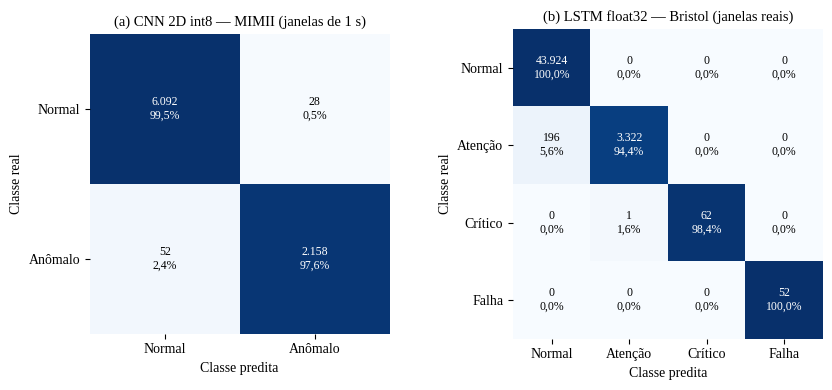

In [4]:
# 4. Figura: matrizes de confusão (contagem e porcentagem da linha = recall de cada classe)
def matriz(ax, cm, rotulos, titulo):
    lin = cm.sum(1, keepdims=True); pct = np.divide(cm, lin, out=np.zeros(cm.shape), where=lin > 0)
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=1)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            cor = "white" if pct[i, j] > 0.6 else "black"
            ax.text(j, i, f"{cm[i, j]:,}".replace(",", ".") + f"\n{100 * pct[i, j]:.1f}%".replace(".", ","),
                    ha="center", va="center", fontsize=8.5, color=cor)
    ax.set_xticks(range(len(rotulos)), rotulos); ax.set_yticks(range(len(rotulos)), rotulos)
    ax.set_xlabel("Classe predita"); ax.set_ylabel("Classe real"); ax.set_title(titulo)
    for s in ax.spines.values(): s.set_visible(False)

fig, ax = plt.subplots(1, 2, figsize=(9.2, 4.0), gridspec_kw={"width_ratios": [1, 1.55]})
matriz(ax[0], cm_cnn, ["Normal", "Anômalo"], "(a) CNN 2D int8 — MIMII (janelas de 1 s)")
matriz(ax[1], cm_lstm, ["Normal", "Atenção", "Crítico", "Falha"], "(b) LSTM float32 — Bristol (janelas reais)")
plt.tight_layout()
for ext in ["png", "svg"]: plt.savefig(f"{SAIDA}/Figura_matrizes_confusao.{ext}")
plt.show()

AUC média na máquina nova: {'v2 (passo 1)': 0.924, 'v3 (passo 2)': 0.905}


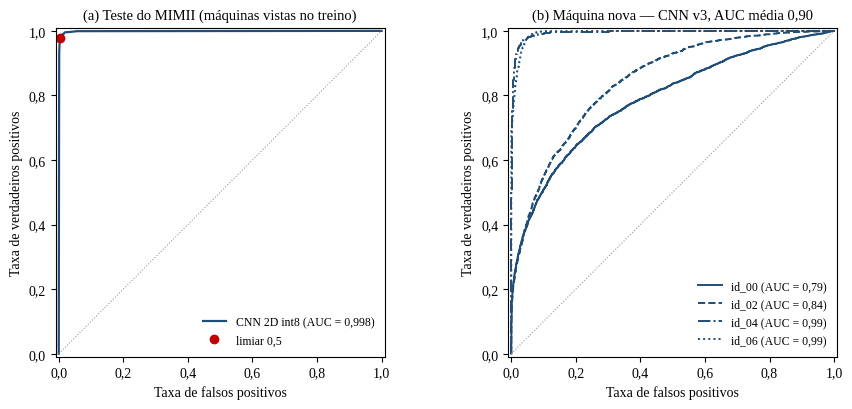

In [5]:
# 5. Figura: curvas ROC (teste principal e máquina nova)
fig, ax = plt.subplots(1, 2, figsize=(9.2, 4.2))
fpr, tpr, lim = roc_curve(yte, p_cnn)
ax[0].plot(fpr, tpr, color="#1f4e79", lw=1.6, label=f"CNN 2D int8 (AUC = {auc_cnn:.3f})".replace(".", ","))
k = np.argmin(np.abs(lim - 0.5))
ax[0].plot(fpr[k], tpr[k], "o", color="#c00000", ms=6, label="limiar 0,5")
ax[0].set_title("(a) Teste do MIMII (máquinas vistas no treino)")

ARQ = f"{CNN}/predicoes_maquina_nova.npz"
if os.path.exists(ARQ):
    P = np.load(ARQ)
    maqs = sorted({k.split("|")[0] for k in P.files})
    estilos = ["-", "--", "-.", ":"]
    aucs = {"v2 (passo 1)": [], "v3 (passo 2)": []}
    for i, m in enumerate(maqs):
        for nome in aucs:
            y, p = P[f"{m}|{nome}|y"], P[f"{m}|{nome}|p"]
            aucs[nome].append(roc_auc_score(y, p))
            if nome.startswith("v3"):
                f, t, _ = roc_curve(y, p)
                ax[1].plot(f, t, estilos[i % 4], color="#1f4e79", lw=1.4,
                           label=f"{m} (AUC = {aucs[nome][-1]:.2f})".replace(".", ","))
    ax[1].set_title(f"(b) Máquina nova — CNN v3, AUC média {np.mean(aucs['v3 (passo 2)']):.2f}".replace(".", ","))
    print("AUC média na máquina nova:", {n: round(float(np.mean(v)), 3) for n, v in aucs.items()})
else:
    ax[1].text(0.5, 0.5, "Rode a célula 8 do notebook 03 v3", ha="center", va="center")
for a in ax:
    a.plot([0, 1], [0, 1], color="0.6", lw=0.8, ls=":")
    a.set_xlabel("Taxa de falsos positivos"); a.set_ylabel("Taxa de verdadeiros positivos")
    a.set_xlim(-0.01, 1.01); a.set_ylim(-0.01, 1.01); a.set_aspect("equal"); a.legend(loc="lower right", fontsize=8.5, frameon=False)
    virgula = plt.FuncFormatter(lambda v, _: f"{v:.1f}".replace(".", ","))
    a.xaxis.set_major_formatter(virgula); a.yaxis.set_major_formatter(virgula)
plt.tight_layout()
for ext in ["png", "svg"]: plt.savefig(f"{SAIDA}/Figura_curvas_ROC.{ext}")
plt.show()

In [6]:
# Exporta os dados da Figura 15 (curvas ROC) e baixa o arquivo
import os
exp = {"yte": yte.astype(np.int8), "p_cnn": p_cnn.astype(np.float32)}
P = np.load(f"{CNN}/predicoes_maquina_nova.npz")
for k in P.files:
    if "v3" in k:                                   # só a CNN v3 entra na figura
        nome = k.replace("|", "__").replace(" ", "_").replace("(", "").replace(")", "")
        exp[nome] = P[k]
caminho = f"{SAIDA}/dados_figura_15.npz"
np.savez_compressed(caminho, **exp)
print("Chaves:", list(exp))
print("Existe:", os.path.exists(caminho), "| tamanho:", os.path.getsize(caminho), "bytes")
from google.colab import files
files.download(caminho)

Chaves: ['yte', 'p_cnn', 'id_00__v3_passo_2__y', 'id_00__v3_passo_2__p', 'id_02__v3_passo_2__y', 'id_02__v3_passo_2__p', 'id_04__v3_passo_2__y', 'id_04__v3_passo_2__p', 'id_06__v3_passo_2__y', 'id_06__v3_passo_2__p']
Existe: True | tamanho: 173366 bytes


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Resultado

Em `dissertacao_tinyml/figuras/`: `Figura_matrizes_confusao.png/.svg` e `Figura_curvas_ROC.png/.svg`, para a seção 8.2.